  <img src="https://raw.githubusercontent.com/scalabrinig/cdProjetoAplicadoIV/d093146488f56dfcf0ef286bcee8efe0e71b9c76/figuras/mackenzie_logo.jpg" width="25%" align="right"/>

# **PROJETO APLICADO IV - Ciência de Dados EaD - 2026/02**


# **Documentação do Projeto**

---

# **Análise e Previsão da Taxa de Desemprego no Brasil por Níveis de Escolaridade**
---

In [ ]:
#@title **Identificação do Grupo**

#@markdown Integrantes do Grupo, nome completo em ordem alfabética (*informe: \<nome\>, \<matrícula\>*)
Aluno1 = 'Lucas Iglezias dos Anjos, 10433522' #@param {type:"string"}
Aluno2 = 'Paulo Ricardo de Oliveira Ramos, 10721464' #@param {type:"string"}
Aluno3 = 'Thaís Cristine de Andrade Gomes, 10721642' #@param {type:"string"}


# **Resumo**

Este projeto analisa o comportamento da taxa de desemprego no Brasil ao longo do tempo, considerando diferentes níveis de escolaridade como dimensão principal e sexo e faixa etária como dimensões complementares. Para isso, foram utilizados dados trimestrais da base estatística da Organização Internacional do Trabalho (ILOSTAT), referentes ao período de 2012T1 a 2026T1, após o recorte temporal da base original. O estudo contempla a análise exploratória dos dados, o pré-processamento e a aplicação de métodos de previsão de séries temporais. Foram implementados cinco modelos: ingênuo, ingênuo sazonal, autorregressivo integrado de médias móveis sazonal (SARIMA), suavização exponencial (ETS, do inglês Error, Trend, Seasonal, no método de Holt-Winters) e regressão Ridge. O desempenho dos modelos é avaliado por meio de métricas de erro e procedimentos de validação temporal, com o objetivo de comparar sua capacidade de previsão para diferentes séries de desemprego segundo a escolaridade. O trabalho busca contribuir para a compreensão da evolução do desemprego no Brasil e das possibilidades e limitações do uso de modelos de séries temporais nesse contexto.

# **Introdução**

O desemprego é um dos indicadores utilizados para acompanhar as condições do mercado de trabalho e sua evolução ao longo do tempo. De acordo com a Organização Internacional do Trabalho (OIT), a taxa de desemprego corresponde à proporção de pessoas desempregadas em relação à força de trabalho, sendo utilizada para acompanhar a disponibilidade e o acesso ao trabalho em diferentes grupos da população (INTERNATIONAL LABOUR ORGANIZATION, 2019). Por apresentar variações ao longo do tempo e poder ser analisada segundo diferentes características da população, como sexo, idade e escolaridade, a taxa de desemprego pode ser estudada por meio de séries temporais.<br>
Neste projeto, é analisada a taxa de desemprego no Brasil a partir de dados trimestrais disponibilizados pelo ILOSTAT, da Organização Internacional do Trabalho. A base utilizada corresponde ao conjunto *Unemployment rate by sex, age and education (%)* e apresenta informações sobre a taxa de desemprego segundo sexo, faixa etária e nível de escolaridade. O arquivo original contém 29.870 registros, distribuídos em 58 trimestres, de 2012T1 a 2026T2. Para manter a comparabilidade com as etapas anteriores do projeto, a análise foi delimitada até 2026T1, resultando em 29.339 registros e 57 trimestres, abrangendo o período de 2012T1 a 2026T1 (INTERNATIONAL LABOUR ORGANIZATION, 2026).<br>
Para o desenvolvimento do projeto, a escolaridade será utilizada como principal dimensão de análise, enquanto sexo e faixa etária serão considerados como dimensões complementares. O estudo será concentrado na população de 15 anos ou mais e nas categorias de escolaridade que apresentarem condições adequadas para a análise temporal. A categoria Total será utilizada como referência geral, permitindo comparar seu comportamento com as séries correspondentes aos diferentes níveis de escolaridade.<br>
A escolha do tema está relacionada à importância de compreender a evolução do desemprego e possíveis diferenças entre grupos com características educacionais distintas. Além da análise histórica, o projeto pretende avaliar a utilização de técnicas de séries temporais para estimar valores futuros da taxa de desemprego. Dessa forma, a contribuição esperada consiste em caracterizar o comportamento das séries segundo a escolaridade e, a partir das características identificadas, avaliar técnicas de previsão que possam ser utilizadas para estimar valores futuros.<br>
O projeto também está relacionado ao Objetivo de Desenvolvimento Sustentável 8 (ODS 8), que trata de trabalho decente e crescimento econômico. Nesse contexto, a análise de indicadores relacionados ao mercado de trabalho contribui para a compreensão de sua evolução e para a identificação de padrões que possam ser estudados por meio de métodos quantitativos.<br>
Como os dados são observados em intervalos regulares e organizados cronologicamente, o problema pode ser tratado como uma série temporal. Segundo Morettin e Toloi (2018), o estudo de séries temporais envolve tanto a investigação e modelagem do comportamento dos dados quanto a previsão de valores futuros. Assim, inicialmente serão investigadas as características das séries selecionadas e, posteriormente, serão avaliadas técnicas de previsão adequadas aos padrões identificados.<br>
O objetivo geral é analisar o comportamento da taxa de desemprego no Brasil ao longo do tempo, considerando diferentes níveis de escolaridade como principal dimensão de análise e sexo e faixa etária como dimensões complementares. A partir dessa análise, pretende-se avaliar técnicas de séries temporais capazes de produzir previsões da taxa de desemprego.<br>
Para alcançar esse objetivo, foram definidos os seguintes objetivos específicos:


*   analisar a evolução da taxa de desemprego no período disponível na base;
*   comparar o comportamento da taxa de desemprego entre diferentes níveis de escolaridade;
*   observar diferenças entre sexo e faixa etária como dimensões complementares;
*   identificar características relevantes nas séries temporais;
*   investigar técnicas de previsão adequadas às características observadas;
*   avaliar e comparar o desempenho dos modelos utilizados.

# **Referencial Teórico**



**1.   Séries temporais**<br>
Uma série temporal é formada por observações de determinada variável realizadas periodicamente e organizadas de acordo com a ordem temporal. Diferentemente de dados sem ordenação temporal, as observações de uma série podem apresentar relação com valores observados anteriormente. O estudo de séries temporais pode ter como objetivos a investigação do comportamento dos dados, sua modelagem e a previsão de valores futuros (MORETTIN; TOLOI, 2018).<br>
A taxa de desemprego é uma variável que pode ser analisada dessa forma, pois seus valores são observados ao longo de períodos sucessivos. O comportamento da série pode apresentar diferentes características, como tendência, sazonalidade, ciclos e variações irregulares. A tendência representa a direção predominante dos valores ao longo do tempo, enquanto a sazonalidade corresponde a padrões que se repetem em intervalos regulares. Os ciclos representam movimentos de crescimento e redução que não necessariamente apresentam período fixo, enquanto o ruído corresponde às variações não explicadas pelos demais componentes (MORETTIN; TOLOI, 2018).

**2.   Autocorrelação e estacionariedade**<br>
A análise de uma série temporal também envolve a investigação da relação entre observações em diferentes momentos. A autocorrelação permite verificar a relação entre os valores atuais e valores anteriores da própria série, considerando diferentes defasagens. A função de autocorrelação (*Autocorrelation Function* — ACF) e a função de autocorrelação parcial (*Partial Autocorrelation Function* — PACF) são ferramentas utilizadas para investigar esse comportamento e podem auxiliar na identificação de características relevantes para a modelagem.<br>
Outro aspecto importante é a estacionariedade. Uma série estacionária apresenta propriedades estatísticas que não dependem do momento em que a observação é realizada. A presença de tendência ou sazonalidade pode tornar a série não estacionária, sendo necessário investigar essa característica antes da aplicação de determinadas técnicas de modelagem (MORETTIN; TOLOI, 2018).

**3.   Técnicas utilizadas em trabalhos relacionados**<br>
Estudos sobre previsão da taxa de desemprego mostram a utilização de diferentes técnicas de séries temporais. Mahmudah (2017), por exemplo, utilizou dados anuais da taxa de desemprego da Indonésia entre 1986 e 2015 e aplicou modelos autorregressivos integrados de médias móveis (ARIMA). A autora identificou a não estacionariedade da série e utilizou diferenciação antes da modelagem, obtendo como melhor modelo o ARIMA (0,2,1). O estudo demonstra a possibilidade de utilização de modelos ARIMA em séries de desemprego, inclusive quando é necessário realizar diferenciação para tratar a não estacionariedade.<br>
Yamacli e Yamacli (2023) compararam modelos ARIMA e redes neurais artificiais para estimar a taxa de desemprego da Turquia utilizando 176 observações mensais entre 2008 e 2022. O estudo considerou também o período da pandemia de COVID-19 e mostrou que o desempenho das abordagens pode variar de acordo com o período analisado. Os resultados indicam que modelos estatísticos e métodos de aprendizado de máquina podem apresentar comportamentos diferentes diante de alterações relevantes na série.<br>
Outro trabalho relacionado é a tese de Alves (2024), que analisou as taxas de desemprego dos países do BRICS e aplicou diferentes métodos de previsão, incluindo redes neurais artificiais, ARIMA, suavização exponencial e decomposição sazonal e tendência por meio de Loess (STL, do inglês *Seasonal and Trend decomposition using Loess*). A utilização de diferentes métodos reforça a importância de considerar as características das séries antes da escolha da técnica de previsão.<br>
Os trabalhos analisados apresentam diferentes alternativas para a previsão de taxas de desemprego. Modelos como ARIMA apresentam como vantagem a utilização da própria estrutura temporal da série e podem ser adequados quando existem relações temporais bem definidas. Como limitação, seu desempenho pode ser afetado por alterações estruturais ou comportamentos que não sejam bem representados pela estrutura do modelo. Métodos de aprendizado de máquina, como redes neurais, permitem representar relações mais complexas, mas podem demandar maior quantidade de dados e uma etapa de preparação mais cuidadosa. Métodos de suavização e decomposição também podem ser utilizados quando a série apresenta componentes de tendência e sazonalidade relevantes.<br>
Dessa forma, a escolha da técnica de previsão não será definida exclusivamente a partir de um modelo específico. A análise exploratória da série será utilizada para identificar suas características e orientar a seleção das técnicas que serão implementadas nas etapas posteriores do projeto.

# **Diagrama de Solução**

O pipeline proposto organiza as principais etapas do desenvolvimento do projeto, desde a seleção e preparação dos dados até a avaliação e interpretação das previsões.<br>


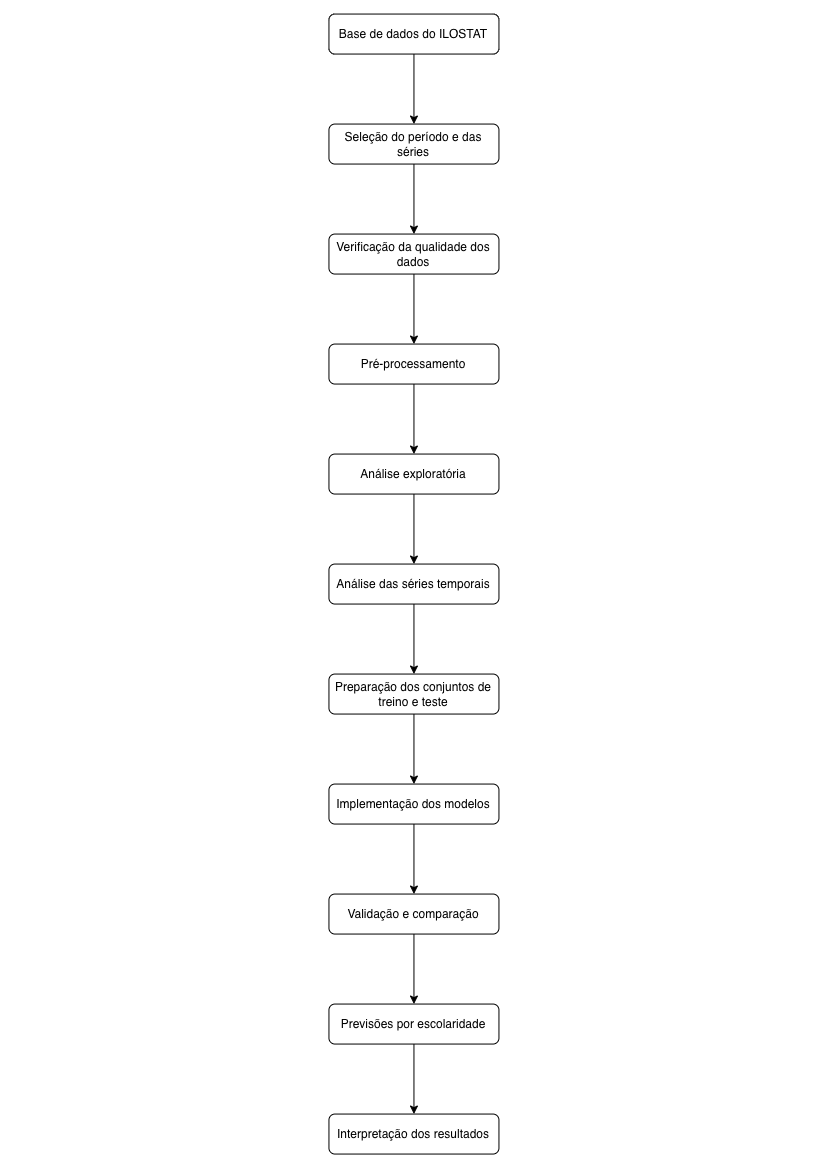<br>

O processo utiliza a base do ILOSTAT, que contém dados trimestrais sobre a taxa de desemprego no Brasil segundo sexo, faixa etária e escolaridade. A base original contém 29.870 registros, distribuídos em 58 trimestres, de 2012T1 a 2026T2. Para manter a comparabilidade com as etapas anteriores do projeto, foi adotado o recorte até 2026T1, resultando em 29.339 registros e 57 trimestres.<br>
Inicialmente, foram selecionados o período de análise e as séries de interesse, considerando a população de 15 anos ou mais e o sexo Total para a modelagem principal. A escolaridade foi utilizada como dimensão central da análise, com as categorias Inferior ao Básico, Básico e Intermediário, além da série Total como referência. A categoria Superior (Avançado) foi mantida fora da modelagem principal, conforme definido na etapa anterior. Em seguida, foram verificados a qualidade dos dados, os valores ausentes, os registros classificados como não confiáveis e a continuidade das observações.<br>
Após a seleção, os dados foram organizados em séries temporais trimestrais e submetidos à análise exploratória, incluindo a avaliação da evolução ao longo do tempo, da sazonalidade e das diferenças entre os níveis de escolaridade. Na sequência, foram preparados os dados para a modelagem, com separação temporal entre treino e teste.<br>
Foram implementados modelos de referência, incluindo os métodos ingênuo e ingênuo sazonal, além de modelos SARIMA, ETS/Holt-Winters e regressão Ridge. O desempenho dos modelos está sendo avaliado por meio de métricas de erro e procedimentos de validação temporal, preservando a ordem cronológica das observações. As próximas etapas envolvem concluir a comparação, realizar os ajustes necessários, selecionar os modelos mais adequados e analisar as previsões por escolaridade.<br>
Por fim, os resultados serão interpretados considerando o comportamento das séries e as limitações dos dados, com atualização da documentação e do repositório do projeto para a entrega final.

# **Cronograma**
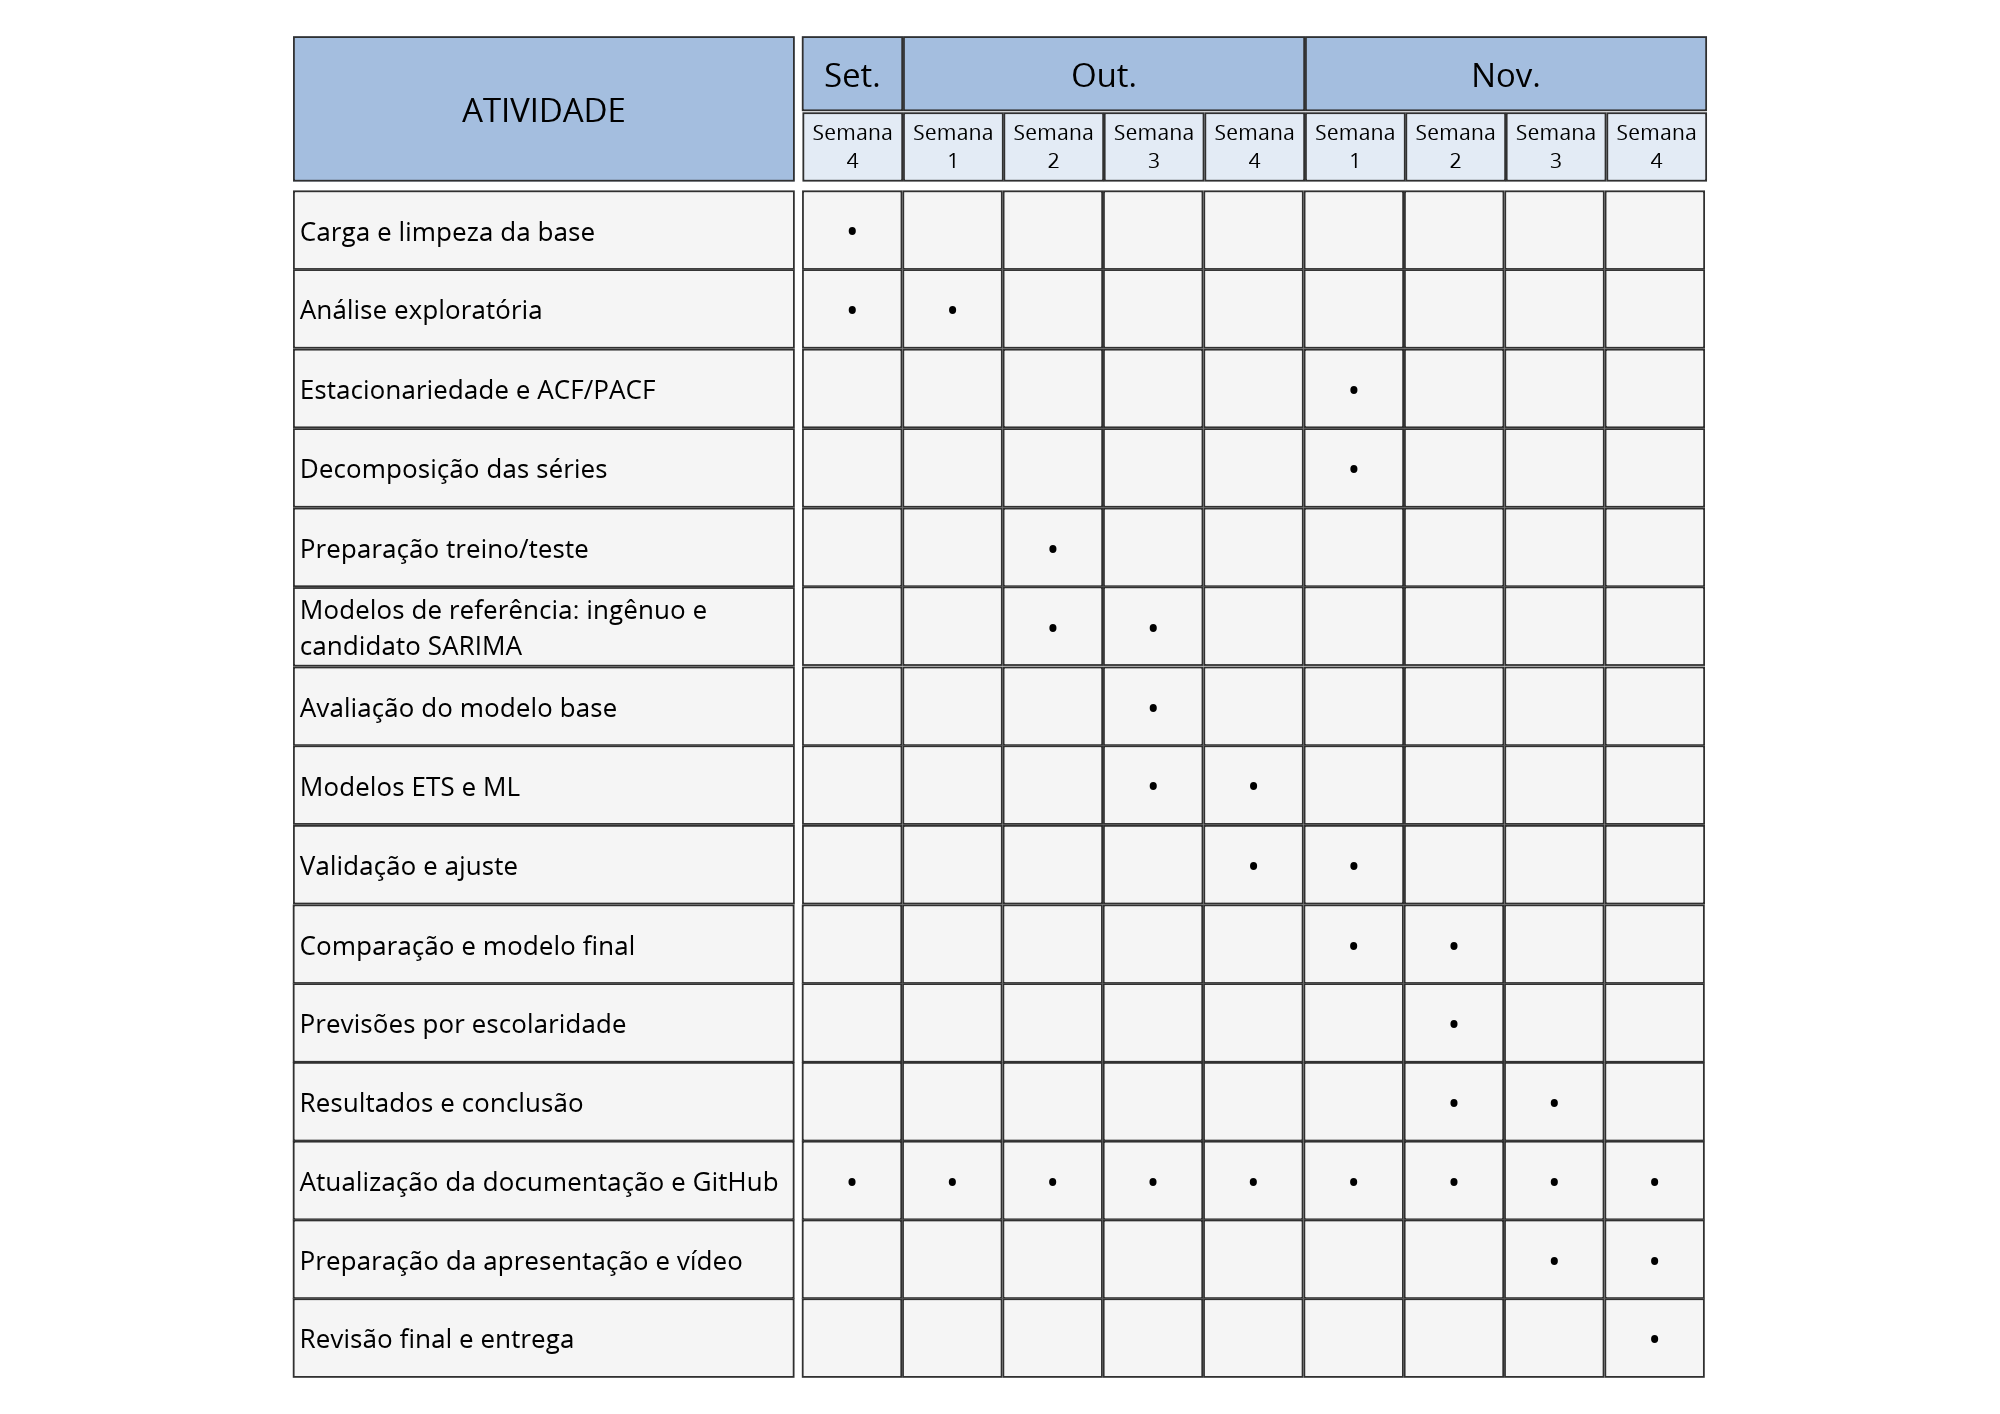<br>
O desenvolvimento do projeto está sendo realizado de forma progressiva, abrangendo a preparação dos dados, a análise exploratória, o pré-processamento e a implementação inicial dos modelos de previsão. Até a terceira etapa, foram realizadas a carga e a seleção dos dados do ILOSTAT, a verificação da qualidade das observações, a análise do comportamento temporal das séries e a preparação dos dados para a modelagem.<br>
Também foram implementados modelos iniciais de referência e métodos de previsão, incluindo modelos ingênuos, SARIMA, ETS/Holt-Winters e regressão Ridge. As etapas seguintes concentram-se na avaliação comparativa dos modelos, na validação temporal e nos ajustes necessários para selecionar a abordagem mais adequada a cada série.<br>
Após essa etapa, serão elaboradas e analisadas as previsões por nível de escolaridade, considerando as limitações identificadas nos dados e o desempenho dos modelos. A documentação e o repositório do projeto continuarão sendo atualizados ao longo do desenvolvimento, seguidos da preparação da apresentação, do vídeo e da revisão final dos artefatos para a entrega da etapa final.

# **EDA e Pré-processamento dos dados**

A análise exploratória foi realizada para avaliar a estrutura, a qualidade e o comportamento temporal da base do ILOSTAT antes da aplicação dos modelos de previsão. O arquivo original contém 29.870 registros, distribuídos em 58 trimestres, de 2012T1 a 2026T2. Para manter a comparabilidade com as etapas anteriores do projeto, foi adotado o recorte até 2026T1, resultando em 29.339 registros e 57 trimestres.<br>
A auditoria global identificou problemas de qualidade em diferentes categorias de escolaridade, especialmente em “Não Declarado”, que apresenta 752 valores ausentes e 1.326 registros classificados como não confiáveis. Também foram identificados registros não confiáveis nas categorias “Inferior ao Básico”, “Básico”, “Intermediário” e “Superior (Avançado)”. Esses resultados demonstram a importância de avaliar a qualidade das observações antes de selecionar as séries utilizadas na modelagem.<br>
No recorte principal, correspondente à população de 15 anos ou mais e ao sexo total, as cinco séries de escolaridade apresentam 57 trimestres, sem valores ausentes ou registros classificados como não confiáveis. Foi identificada apenas uma marcação de quebra de série, em 2012T1, em cada uma delas, discutida ao final desta seção.<br>
As estatísticas descritivas indicam diferenças entre os níveis de escolaridade. No período analisado, a taxa média de desemprego foi de 11,289% para a categoria “Básico”, 10,816% para “Intermediário”, 7,575% para “Inferior ao Básico” e 4,942% para “Superior (Avançado)”. A série total apresentou média de 9,580%. Portanto, a categoria “Básico” apresentou a maior média entre as séries consideradas, enquanto “Superior (Avançado)” apresentou a menor.<br>
A evolução trimestral também revela variações importantes ao longo do tempo. As taxas aumentam durante a crise econômica de 2015–2016 e apresentam elevação expressiva durante a pandemia de COVID-19, especialmente em 2020–2021. Nos trimestres posteriores, observa-se uma redução geral das taxas. Os gráficos de sazonalidade sugerem diferenças entre os trimestres do ano, mas a magnitude dessas diferenças varia conforme a escolaridade.<br>
Como dimensão complementar, a análise por sexo mostra médias de desemprego feminino superiores às masculinas em todas as categorias apresentadas. Na série total, a média foi de 11,593% para mulheres e 8,037% para homens. A análise por faixa etária também evidencia diferenças entre grupos, com taxas médias mais elevadas entre pessoas de 15 a 24 anos do que entre as faixas etárias mais velhas.<br>
Com base nesses diagnósticos, foram selecionadas para a modelagem as séries “Total (Referência)”, “Inferior ao Básico”, “Básico” e “Intermediário”, mantendo a série total como referência geral. A categoria “Superior (Avançado)” foi mantida fora da modelagem principal, conforme definido na etapa anterior do projeto. Embora esteja completa no recorte principal utilizado na modelagem, essa categoria apresenta 48 valores ausentes e 212 registros classificados como não confiáveis na base global, o que limita seu uso em análises mais detalhadas por sexo e faixa etária. Sua inclusão poderá ser reavaliada na etapa final do projeto. A categoria “Não Declarado” também não foi incluída, por não representar um nível de escolaridade e por concentrar 752 valores ausentes e 1.326 registros não confiáveis na base global, além de 11 registros não confiáveis no recorte principal.<br>
Após o recorte e a seleção das séries, os dados foram organizados cronologicamente para permitir a aplicação dos métodos de previsão de séries temporais. As decisões de preparação buscaram manter a consistência com as etapas anteriores do projeto e reduzir problemas de comparabilidade. A única quebra de série sinalizada ocorre em 2012T1, primeiro trimestre da base analisada, e está associada ao início da metodologia revisada da PNAD Contínua. Como não há observações anteriores a esse marco no período considerado, essa indicação não compromete a comparabilidade temporal da série utilizada neste estudo.

Ficheiro 'UNE_DEAP_SEX_AGE_EDU_RT_Q-filtered-2026-10-25.csv' não encontrado no diretório atual.
Por favor, selecione o ficheiro CSV no botão abaixo para fazer o envio:


Saving UNE_DEAP_SEX_AGE_EDU_RT_Q-filtered-2026-10-25.csv to UNE_DEAP_SEX_AGE_EDU_RT_Q-filtered-2026-10-25.csv
1. DIAGNÓSTICO ESTRUTURAL DA BASE BRUTA (ILOSTAT)
-> Total de registos no ficheiro bruto: 29,870 linhas x 12 colunas
-> Intervalo total no CSV: 2012T1 até 2026T2 (58 trimestres)
-> Base alinhada ao escopo do projeto (até 2026T1): 29,339 linhas | 57 trimestres

2. AUDITORIA DE QUALIDADE DOS DADOS (BASE GLOBAL vs. RECORTE 15+ TOTAL)


#### **Tabela 2.1: Auditoria de Qualidade na Base Global (Todas as Faixas Etárias e Sexos)**

,Total de Registos,Valores Ausentes (Nulos),Registos Não Confiáveis,Quebras de Série
Escolaridade,,,,
Total (Referência),2736,0,0,48
Inferior ao Básico,2736,6,95,46
Básico,2736,2,48,46
Intermediário,2736,18,146,42
Superior (Avançado),2736,48,212,42
Não Declarado,2208,752,1326,32


#### **Tabela 2.2: Auditoria no Recorte Principal (População de 15 anos ou mais, Sexo = Total)**

...

#### **Tabela 4.1: Comparação da Taxa de Desemprego por Sexo e Escolaridade (População 15+)**

,Feminino - Média (%),Masculino - Média (%),Diferença entre Sexos (F - M),Razão (F / M)
Escolaridade,,,,
Total (Referência),11.593%,8.037%,+3.556 p.p.,1.44x
Inferior ao Básico,9.092%,6.962%,+2.129 p.p.,1.31x
Básico,14.536%,9.439%,+5.097 p.p.,1.54x
Intermediário,13.382%,8.607%,+4.775 p.p.,1.55x
Superior (Avançado),5.749%,3.957%,+1.793 p.p.,1.45x


#### **Tabela 4.2: Taxa Média de Desemprego por Faixa Etária x Escolaridade (Sexo = Total)**

Escolaridade,Total (Referência),Inferior ao Básico,Básico,Intermediário,Superior (Avançado)
Faixa Etária,,,,,
15 a 24 anos,21.484%,18.992%,25.283%,19.933%,13.452%
25 a 54 anos,7.526%,8.459%,8.510%,8.255%,4.757%
55 a 64 anos,4.691%,5.469%,5.105%,4.861%,2.920%
65 anos ou mais,2.436%,2.334%,2.637%,2.769%,2.030%



5. A GERAR PAINÉIS GRÁFICOS DA ANÁLISE EXPLORATÓRIA (EM PORTUGUÊS)


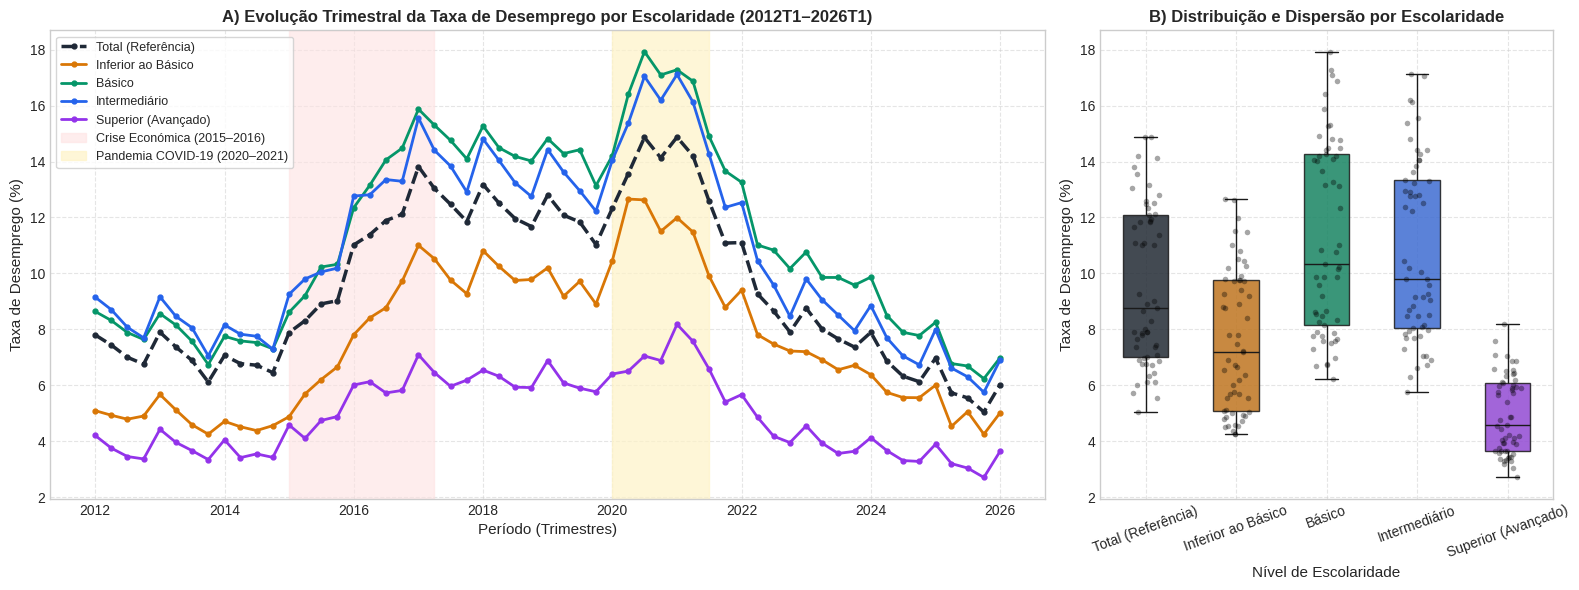

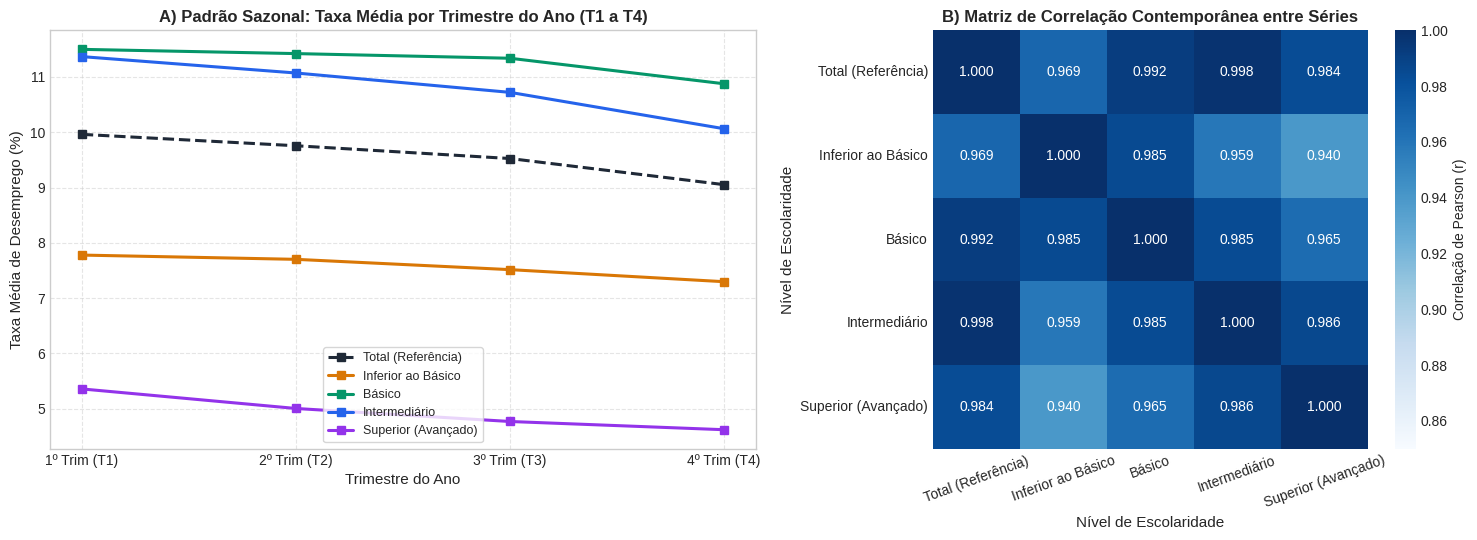

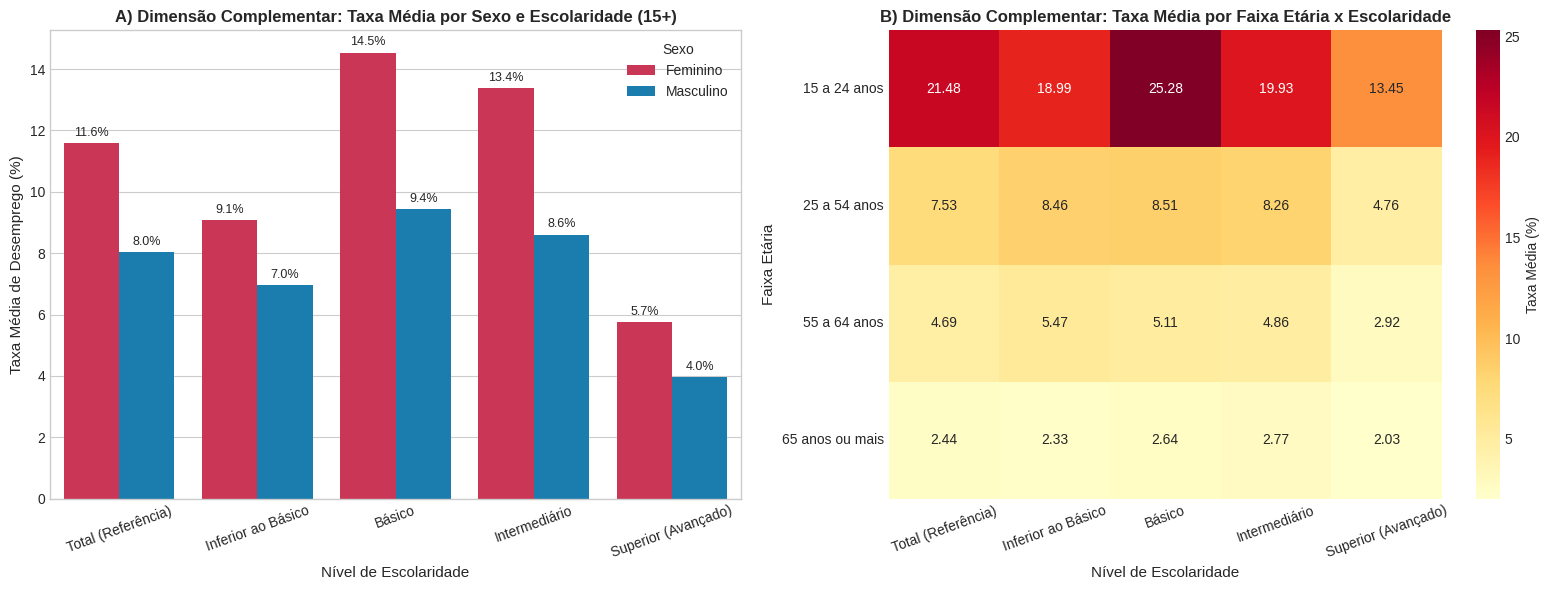

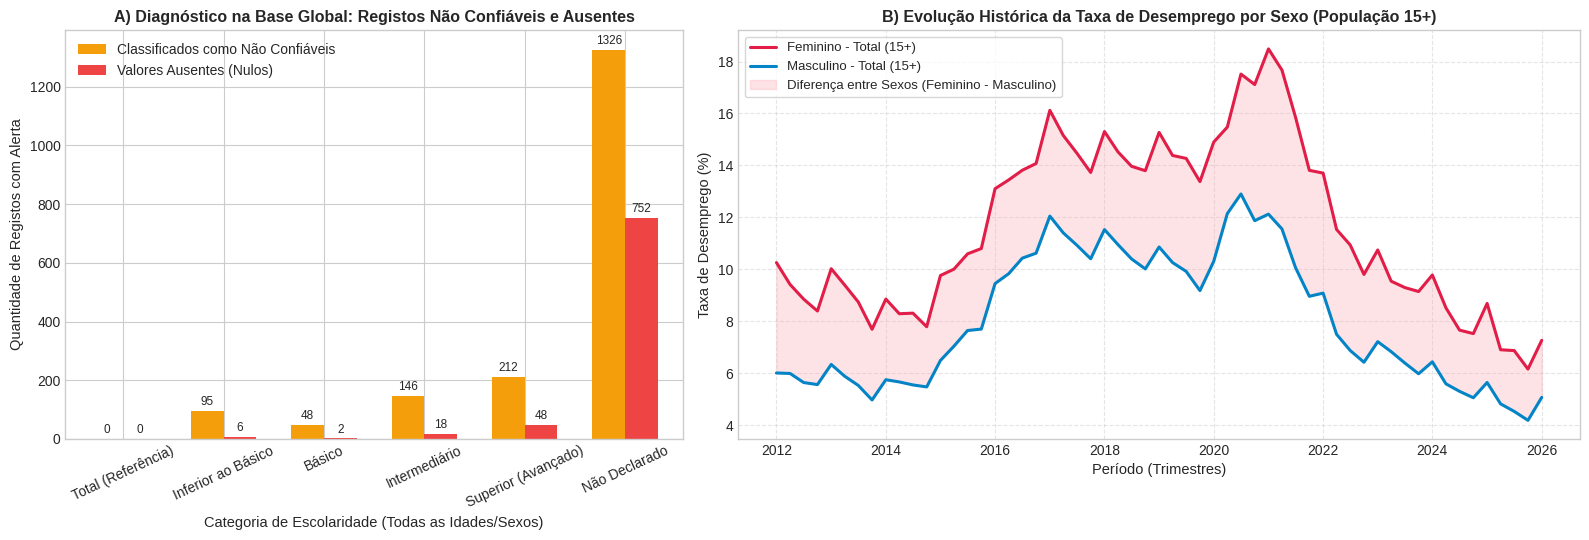


6. EXPORTAÇÃO DAS BASES LIMPAS E PRÉ-PROCESSADAS (EM PORTUGUÊS)
-> Ficheiro guardado: 'serie_temporal_desemprego_modelagem_estrita_pt.csv' (57 trimestres x 4 séries)
-> Ficheiro guardado: 'serie_temporal_desemprego_modelagem_completa_pt.csv' (57 trimestres x 5 séries)
-> Pré-processamento e EDA em Português concluídos com sucesso!


In [1]:
# ==============================================================================
# Etapa 1: Análise Exploratória de Dados (EDA) e Pré-Processamento (100% PT)
# ==============================================================================

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'sans-serif'

# ------------------------------------------------------------------------------
# 1. CARREGAMENTO E TRADUÇÃO DOS RÓTULOS DA BASE DE DADOS
# ------------------------------------------------------------------------------
NOME_FICHEIRO = 'UNE_DEAP_SEX_AGE_EDU_RT_Q-filtered-2026-10-25.csv'

if not os.path.exists(NOME_FICHEIRO):
    try:
        from google.colab import files
        print(f"Ficheiro '{NOME_FICHEIRO}' não encontrado no diretório atual.")
        print("Por favor, selecione o ficheiro CSV no botão abaixo para fazer o envio:")
        enviados = files.upload()
        NOME_FICHEIRO = list(enviados.keys())[0]
    except ImportError:
        raise FileNotFoundError(f"Coloque o ficheiro '{NOME_FICHEIRO}' na mesma pasta do script.")

df_bruto = pd.read_csv(NOME_FICHEIRO)

print("="*80)
print("1. DIAGNÓSTICO ESTRUTURAL DA BASE BRUTA (ILOSTAT)")
print("="*80)
print(f"-> Total de registos no ficheiro bruto: {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas")
print(f"-> Intervalo total no CSV: {df_bruto['time'].min().replace('Q', 'T')} até {df_bruto['time'].max().replace('Q', 'T')} ({df_bruto['time'].nunique()} trimestres)")

# Alinhamento com o escopo documentado no projeto (2012Q1 a 2026Q1 = 57 trimestres)
CORTE_MAX_TEMPO = '2026Q1'
df = df_bruto[df_bruto['time'] <= CORTE_MAX_TEMPO].copy()
print(f"-> Base alinhada ao escopo do projeto (até 2026T1): {df.shape[0]:,} linhas | {df['time'].nunique()} trimestres")

# Dicionários de tradução para Português
mapa_escolaridade = {
    'Education (Aggregate levels): Total': 'Total (Referência)',
    'Education (Aggregate levels): Less than basic': 'Inferior ao Básico',
    'Education (Aggregate levels): Basic': 'Básico',
    'Education (Aggregate levels): Intermediate': 'Intermediário',
    'Education (Aggregate levels): Advanced': 'Superior (Avançado)',
    'Education (Aggregate levels): Level not stated': 'Não Declarado'
}

mapa_sexo = {
    'Total': 'Total',
    'Female': 'Feminino',
    'Male': 'Masculino'
}

mapa_status = {
    'Unreliable': 'Não Confiável',
    'Break in series': 'Quebra de Série'
}

mapa_trimestre = {
    'Q1': '1º Trim (T1)',
    'Q2': '2º Trim (T2)',
    'Q3': '3º Trim (T3)',
    'Q4': '4º Trim (T4)'
}

mapa_notas = {
    'Frequency: Quarterly: average based on 3 monthly data points': 'Frequência: Trimestral (média de 3 meses)',
    'Frequency: Quarterly: average based on 3 monthly data points | Break in series: Methodology revised': 'Frequência: Trimestral | Quebra de série: Metodologia revista'
}

ordem_cols = ['Total (Referência)', 'Inferior ao Básico', 'Básico', 'Intermediário', 'Superior (Avançado)']

# Aplicar traduções
df['Sexo'] = df['sex.label'].map(mapa_sexo)
df['Status_Observacao'] = df['obs_status.label'].map(mapa_status).fillna('Normal')
df['Nota_Indicador'] = df['note_indicator.label'].map(mapa_notas)
df['Trimestre'] = df['time'].str.replace('Q', 'T')

# ------------------------------------------------------------------------------
# 2. AUDITORIA DE QUALIDADE: VALORES AUSENTES, NÃO CONFIÁVEIS E QUEBRAS DE SÉRIE
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("2. AUDITORIA DE QUALIDADE DOS DADOS (BASE GLOBAL vs. RECORTE 15+ TOTAL)")
print("="*80)

# 2.1 Diagnóstico na base global para os níveis agregados de escolaridade
df_agg_global = df[df['classif2.label'].isin(mapa_escolaridade.keys())].copy()
df_agg_global['Escolaridade'] = df_agg_global['classif2.label'].map(mapa_escolaridade)

auditoria_global = df_agg_global.groupby('Escolaridade').agg(
    Total_Linhas=('time', 'count'),
    Valores_Ausentes=('obs_value', lambda x: x.isnull().sum()),
    Registos_Nao_Confiaveis=('Status_Observacao', lambda x: (x == 'Não Confiável').sum()),
    Quebras_de_Serie=('Status_Observacao', lambda x: (x == 'Quebra de Série').sum())
).loc[ordem_cols + ['Não Declarado']]
auditoria_global.columns = ['Total de Registos', 'Valores Ausentes (Nulos)', 'Registos Não Confiáveis', 'Quebras de Série']

display(Markdown("#### **Tabela 2.1: Auditoria de Qualidade na Base Global (Todas as Faixas Etárias e Sexos)**"))
display(auditoria_global)

# 2.2 Aplicação dos filtros principais do projeto: População 15+, Sexo Total
df_principal_todos = df_agg_global[
    (df_agg_global['Sexo'] == 'Total') &
    (df_agg_global['classif1.label'] == 'Age (Youth, adults): 15+')
].copy()

auditoria_recorte = df_principal_todos.groupby('Escolaridade').agg(
    Trimestres_Presentes=('time', 'count'),
    Trimestres_Faltantes=('time', lambda x: 57 - x.nunique()),
    Valores_Ausentes=('obs_value', lambda x: x.isnull().sum()),
    Registos_Nao_Confiaveis=('Status_Observacao', lambda x: (x == 'Não Confiável').sum()),
    Quebras_de_Serie=('Status_Observacao', lambda x: (x == 'Quebra de Série').sum())
).loc[ordem_cols + ['Não Declarado']]
auditoria_recorte.columns = ['Trimestres Presentes', 'Trimestres em Falta', 'Valores Ausentes (Nulos)', 'Registos Não Confiáveis', 'Quebras de Série']

display(Markdown("#### **Tabela 2.2: Auditoria no Recorte Principal (População de 15 anos ou mais, Sexo = Total)**"))
display(auditoria_recorte)

# Detalhamento das quebras de série informadas na fonte
quebras_df = df_principal_todos[df_principal_todos['Status_Observacao'] == 'Quebra de Série'][
    ['Trimestre', 'Escolaridade', 'obs_value', 'Status_Observacao', 'Nota_Indicador']
].rename(columns={'obs_value': 'Taxa (%)', 'Status_Observacao': 'Status da Observação', 'Nota_Indicador': 'Nota Metodológica'})

display(Markdown("#### **Tabela 2.3: Registos com 'Quebra de Série' no Recorte Principal**"))
display(quebras_df)

# Filtrar apenas as categorias válidas de escolaridade (excluindo 'Não Declarado')
df_principal = df_principal_todos[df_principal_todos['Escolaridade'].isin(ordem_cols)].copy()

# ------------------------------------------------------------------------------
# 3. ORGANIZAÇÃO TEMPORAL E ESTATÍSTICAS DESCRITIVAS AVANÇADAS
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("3. ORGANIZAÇÃO DA SÉRIE TEMPORAL E ESTATÍSTICAS DESCRITIVAS")
print("="*80)

# Pivotar para formato de série temporal multivariada
ts_principal = df_principal.pivot(index='time', columns='Escolaridade', values='obs_value')[ordem_cols].sort_index()
ts_datas = pd.PeriodIndex(ts_principal.index, freq='Q').to_timestamp()
ts_principal.index = ts_principal.index.str.replace('Q', 'T')

# Tabela de Estatísticas Descritivas Completa em Português
stats_df = pd.DataFrame({
    'Trimestres (N)': ts_principal.count(),
    'Média (%)': ts_principal.mean(),
    'Desvio-Padrão (%)': ts_principal.std(),
    'Coef. Variação (%)': (ts_principal.std() / ts_principal.mean()) * 100,
    'Mínimo (%)': ts_principal.min(),
    '1º Quartil - 25% (%)': ts_principal.quantile(0.25),
    'Mediana (%)': ts_principal.median(),
    '3º Quartil - 75% (%)': ts_principal.quantile(0.75),
    'Amplitude Interquartil (p.p.)': ts_principal.quantile(0.75) - ts_principal.quantile(0.25),
    'Máximo (%)': ts_principal.max(),
    'Assimetria': ts_principal.skew(),
    'Curtose': ts_principal.kurt()
})

display(Markdown("#### **Tabela 3.1: Estatísticas Descritivas das Taxas de Desemprego por Escolaridade (2012T1–2026T1)**"))
display(stats_df.style.format({
    'Trimestres (N)': '{:.0f}',
    'Média (%)': '{:.3f}',
    'Desvio-Padrão (%)': '{:.3f}',
    'Coef. Variação (%)': '{:.2f}%',
    'Mínimo (%)': '{:.3f}',
    '1º Quartil - 25% (%)': '{:.3f}',
    'Mediana (%)': '{:.3f}',
    '3º Quartil - 75% (%)': '{:.3f}',
    'Amplitude Interquartil (p.p.)': '{:.3f}',
    'Máximo (%)': '{:.3f}',
    'Assimetria': '{:.3f}',
    'Curtose': '{:.3f}'
}))

# Sazonalidade por Trimestre do Ano (T1 a T4)
ts_sazonal = ts_principal.copy()
ts_sazonal['Trimestre do Ano'] = ts_sazonal.index.str[-2:].str.replace('T', 'Q').map(mapa_trimestre)
medias_sazonais = ts_sazonal.groupby('Trimestre do Ano')[ordem_cols].mean().loc[
    ['1º Trim (T1)', '2º Trim (T2)', '3º Trim (T3)', '4º Trim (T4)']
]
amplitude_sazonal = pd.DataFrame(medias_sazonais.loc['1º Trim (T1)'] - medias_sazonais.loc['4º Trim (T4)']).T
amplitude_sazonal.index = ['Amplitude Sazonal (T1 - T4)']
tabela_sazonal = pd.concat([medias_sazonais, amplitude_sazonal])

display(Markdown("#### **Tabela 3.2: Comportamento Sazonal Médio por Trimestre do Ano (T1 a T4)**"))
display(tabela_sazonal.style.format("{:.3f}%"))

# ------------------------------------------------------------------------------
# 4. ANÁLISE DAS DIMENSÕES COMPLEMENTARES: SEXO E FAIXA ETÁRIA
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("4. DIMENSÕES COMPLEMENTARES: SEXO E FAIXA ETÁRIA")
print("="*80)

# 4.1 Dimensão Sexo (Masculino vs Feminino, População 15+)
df_sexo = df_agg_global[
    (df_agg_global['Sexo'].isin(['Masculino', 'Feminino'])) &
    (df_agg_global['classif1.label'] == 'Age (Youth, adults): 15+') &
    (df_agg_global['Escolaridade'].isin(ordem_cols))
].copy()

tabela_sexo = df_sexo.groupby(['Escolaridade', 'Sexo'])['obs_value'].agg(['mean', 'std', 'median', 'min', 'max']).unstack()
resumo_sexo = pd.DataFrame({
    'Feminino - Média (%)': tabela_sexo['mean']['Feminino'],
    'Masculino - Média (%)': tabela_sexo['mean']['Masculino'],
    'Diferença entre Sexos (F - M)': tabela_sexo['mean']['Feminino'] - tabela_sexo['mean']['Masculino'],
    'Razão (F / M)': tabela_sexo['mean']['Feminino'] / tabela_sexo['mean']['Masculino']
}).loc[ordem_cols]

display(Markdown("#### **Tabela 4.1: Comparação da Taxa de Desemprego por Sexo e Escolaridade (População 15+)**"))
display(resumo_sexo.style.format({
    'Feminino - Média (%)': '{:.3f}%',
    'Masculino - Média (%)': '{:.3f}%',
    'Diferença entre Sexos (F - M)': '+{:.3f} p.p.',
    'Razão (F / M)': '{:.2f}x'
}))

# 4.2 Dimensão Faixa Etária (15 a 24, 25 a 54, 55 a 64, 65 anos ou mais)
mapa_idade = {
    'Age (Aggregate bands): 15-24': '15 a 24 anos',
    'Age (Aggregate bands): 25-54': '25 a 54 anos',
    'Age (Aggregate bands): 55-64': '55 a 64 anos',
    'Age (Aggregate bands): 65+': '65 anos ou mais'
}
df_idade = df_agg_global[
    (df_agg_global['Sexo'] == 'Total') &
    (df_agg_global['classif1.label'].isin(mapa_idade.keys())) &
    (df_agg_global['Escolaridade'].isin(ordem_cols))
].copy()
df_idade['Faixa Etária'] = df_idade['classif1.label'].map(mapa_idade)

tabela_idade = df_idade.groupby(['Faixa Etária', 'Escolaridade'])['obs_value'].mean().unstack()[ordem_cols]
tabela_idade = tabela_idade.loc[['15 a 24 anos', '25 a 54 anos', '55 a 64 anos', '65 anos ou mais']]

display(Markdown("#### **Tabela 4.2: Taxa Média de Desemprego por Faixa Etária x Escolaridade (Sexo = Total)**"))
display(tabela_idade.style.format("{:.3f}%"))

# ------------------------------------------------------------------------------
# 5. VISUALIZAÇÕES EXPLORATÓRIAS EM PORTUGUÊS (4 PAINÉIS COMPLETOS)
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("5. A GERAR PAINÉIS GRÁFICOS DA ANÁLISE EXPLORATÓRIA (EM PORTUGUÊS)")
print("="*80)

paleta_pt = {
    'Total (Referência)': '#1f2937',
    'Inferior ao Básico': '#d97706',
    'Básico': '#059669',
    'Intermediário': '#2563eb',
    'Superior (Avançado)': '#9333ea'
}

# --- PAINEL 1: Evolução Temporal + Boxplot ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [2.2, 1]})

for col in ordem_cols:
    ls = '--' if col == 'Total (Referência)' else '-'
    lw = 2.5 if col == 'Total (Referência)' else 2.0
    ax1.plot(ts_datas, ts_principal[col], label=col, color=paleta_pt[col], linestyle=ls, linewidth=lw, marker='o', markersize=3.5)

ax1.axvspan(pd.to_datetime('2015-01-01'), pd.to_datetime('2017-03-31'), color='#fee2e2', alpha=0.6, label='Crise Económica (2015–2016)')
ax1.axvspan(pd.to_datetime('2020-01-01'), pd.to_datetime('2021-06-30'), color='#fef3c7', alpha=0.7, label='Pandemia COVID-19 (2020–2021)')
ax1.set_title('A) Evolução Trimestral da Taxa de Desemprego por Escolaridade (2012T1–2026T1)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Período (Trimestres)', fontsize=11)
ax1.set_ylabel('Taxa de Desemprego (%)', fontsize=11)
ax1.legend(loc='upper left', frameon=True, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.5)

ts_melted = ts_principal.reset_index().melt(id_vars='time', value_vars=ordem_cols, var_name='Escolaridade', value_name='Taxa (%)')
sns.boxplot(data=ts_melted, x='Escolaridade', y='Taxa (%)', palette=paleta_pt, ax=ax2, width=0.5, boxprops=dict(alpha=0.85))
sns.stripplot(data=ts_melted, x='Escolaridade', y='Taxa (%)', color='black', alpha=0.35, size=4, jitter=0.15, ax=ax2)
ax2.set_title('B) Distribuição e Dispersão por Escolaridade', fontsize=12, fontweight='bold')
ax2.set_xlabel('Nível de Escolaridade', fontsize=11)
ax2.set_ylabel('Taxa de Desemprego (%)', fontsize=11)
ax2.tick_params(axis='x', rotation=20)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('painel1_pt_evolucao_distribuicao.png', dpi=300)
plt.show()

# --- PAINEL 2: Sazonalidade Trimestral e Matriz de Correlação ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})

for col in ordem_cols:
    ls = '--' if col == 'Total (Referência)' else '-'
    ax1.plot(medias_sazonais.index, medias_sazonais[col], marker='s', markersize=6, linewidth=2.2, linestyle=ls, color=paleta_pt[col], label=col)

ax1.set_title('A) Padrão Sazonal: Taxa Média por Trimestre do Ano (T1 a T4)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Trimestre do Ano', fontsize=11)
ax1.set_ylabel('Taxa Média de Desemprego (%)', fontsize=11)
ax1.legend(loc='best', frameon=True, fontsize=9)
ax1.grid(True, linestyle='--', alpha=0.5)

matriz_corr = ts_principal.corr()
sns.heatmap(matriz_corr, annot=True, fmt='.3f', cmap='Blues', vmin=0.85, vmax=1.0, cbar_kws={'label': 'Correlação de Pearson (r)'}, ax=ax2)
ax2.set_title('B) Matriz de Correlação Contemporânea entre Séries', fontsize=12, fontweight='bold')
ax2.set_xlabel('Nível de Escolaridade', fontsize=11)
ax2.set_ylabel('Nível de Escolaridade', fontsize=11)
ax2.tick_params(axis='x', rotation=20)
ax2.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('painel2_pt_sazonalidade_correlacao.png', dpi=300)
plt.show()

# --- PAINEL 3: Dimensões Complementares (Sexo e Faixa Etária) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

df_plot_sexo = df_sexo.groupby(['Escolaridade', 'Sexo'])['obs_value'].mean().reset_index()
df_plot_sexo['Escolaridade'] = pd.Categorical(df_plot_sexo['Escolaridade'], categories=ordem_cols, ordered=True)
sns.barplot(data=df_plot_sexo, x='Escolaridade', y='obs_value', hue='Sexo', palette={'Feminino': '#e11d48', 'Masculino': '#0284c7'}, ax=ax1)
ax1.set_title('A) Dimensão Complementar: Taxa Média por Sexo e Escolaridade (15+)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Nível de Escolaridade', fontsize=11)
ax1.set_ylabel('Taxa Média de Desemprego (%)', fontsize=11)
ax1.tick_params(axis='x', rotation=20)
ax1.legend(title='Sexo')
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

sns.heatmap(tabela_idade, annot=True, fmt='.2f', cmap='YlOrRd', cbar_kws={'label': 'Taxa Média (%)'}, ax=ax2)
ax2.set_title('B) Dimensão Complementar: Taxa Média por Faixa Etária x Escolaridade', fontsize=12, fontweight='bold')
ax2.set_xlabel('Nível de Escolaridade', fontsize=11)
ax2.set_ylabel('Faixa Etária', fontsize=11)
ax2.tick_params(axis='x', rotation=20)
ax2.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('painel3_pt_sexo_idade.png', dpi=300)
plt.show()

# --- PAINEL 4: Qualidade dos Dados na Base Global e Série Histórica por Sexo ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.1, 1.5]})

qual_plot = auditoria_global[['Registos Não Confiáveis', 'Valores Ausentes (Nulos)']]
qual_plot.plot(kind='bar', ax=ax1, color=['#f59e0b', '#ef4444'], width=0.65)
ax1.set_title('A) Diagnóstico na Base Global: Registos Não Confiáveis e Ausentes', fontsize=11.5, fontweight='bold')
ax1.set_xlabel('Categoria de Escolaridade (Todas as Idades/Sexos)', fontsize=10.5)
ax1.set_ylabel('Quantidade de Registos com Alerta', fontsize=10.5)
ax1.tick_params(axis='x', rotation=25)
ax1.legend(['Classificados como Não Confiáveis', 'Valores Ausentes (Nulos)'])
for container in ax1.containers:
    ax1.bar_label(container, padding=2, fontsize=8.5)

ts_sexo = df_sexo.pivot_table(index='time', columns=['Sexo', 'Escolaridade'], values='obs_value').sort_index()
ts_sexo_datas = pd.PeriodIndex(ts_sexo.index, freq='Q').to_timestamp()
ax2.plot(ts_sexo_datas, ts_sexo[('Feminino', 'Total (Referência)')], color='#e11d48', lw=2.2, label='Feminino - Total (15+)')
ax2.plot(ts_sexo_datas, ts_sexo[('Masculino', 'Total (Referência)')], color='#0284c7', lw=2.2, label='Masculino - Total (15+)')
ax2.fill_between(ts_sexo_datas, ts_sexo[('Masculino', 'Total (Referência)')], ts_sexo[('Feminino', 'Total (Referência)')], color='#fda4af', alpha=0.3, label='Diferença entre Sexos (Feminino - Masculino)')
ax2.set_title('B) Evolução Histórica da Taxa de Desemprego por Sexo (População 15+)', fontsize=11.5, fontweight='bold')
ax2.set_xlabel('Período (Trimestres)', fontsize=10.5)
ax2.set_ylabel('Taxa de Desemprego (%)', fontsize=10.5)
ax2.legend(loc='upper left', frameon=True, fontsize=9.5)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('painel4_pt_qualidade_e_genero.png', dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 6. EXPORTAÇÃO DAS BASES PRÉ-PROCESSADAS EM PORTUGUÊS PARA A MODELAGEM
# ------------------------------------------------------------------------------
print("\n" + "="*80)
print("6. EXPORTAÇÃO DAS BASES LIMPAS E PRÉ-PROCESSADAS (EM PORTUGUÊS)")
print("="*80)

# Base 1: Escopo estrito do Diagrama de Solução (Total, Inferior ao Básico, Básico, Intermediário)
cols_diagrama_pt = ['Total (Referência)', 'Inferior ao Básico', 'Básico', 'Intermediário']
ts_modelagem_estrita = ts_principal[cols_diagrama_pt].copy()
ts_modelagem_estrita.index.name = 'Trimestre'
ts_modelagem_estrita.to_csv('serie_temporal_desemprego_modelagem_estrita_pt.csv')

# Base 2: Escopo completo incluindo Superior (Avançado)
ts_modelagem_completa = ts_principal.copy()
ts_modelagem_completa.index.name = 'Trimestre'
ts_modelagem_completa.to_csv('serie_temporal_desemprego_modelagem_completa_pt.csv')

print("-> Ficheiro guardado: 'serie_temporal_desemprego_modelagem_estrita_pt.csv' (57 trimestres x 4 séries)")
print("-> Ficheiro guardado: 'serie_temporal_desemprego_modelagem_completa_pt.csv' (57 trimestres x 5 séries)")
print("-> Pré-processamento e EDA em Português concluídos com sucesso!")

# **Modelos**

Descrição metodológica para a criação, refinamento e validação dos modelos propostos.

**Séries modeladas.** Foram modeladas as quatro séries definidas no Diagrama de Solução, com a população de 15 anos ou mais e sexo Total: **Total (Referência)**, **Inferior ao Básico**, **Básico** e **Intermediário**. Cada série é modelada de forma univariada, com 57 observações trimestrais (2012T1–2026T1). A categoria Superior (Avançado) ficou fora desta etapa pelos problemas de qualidade apontados na EDA.<br>

**Divisão temporal.** A ordem cronológica foi preservada. Os **últimos 8 trimestres (2024T2–2026T1)** foram reservados como conjunto de teste, e o treino corresponde a 2012T1–2024T1 (49 trimestres). Como o teste cobre um único período, também foi feita uma **validação com janela expansiva** (*rolling origin*). São 12 origens de previsão (fim do treino de 2022T2 a 2025T1), e em cada origem o modelo é reajustado com todo o histórico disponível até ali e prevê os 4 trimestres seguintes (previsões cobrindo 2022T3–2026T1). As métricas são calculadas para cada origem e depois agregadas pela média.<br>

**Modelos implementados.**

* **Ingênuo sazonal (modelo de referência / base):** repete o valor do mesmo trimestre do ano anterior, ŷ(t+h) = y(t+h−4). É a referência mínima que os demais modelos precisam superar. Também foi incluído o **ingênuo simples** (repete o último valor) para comparação.
* **SARIMA(p,d,q)(P,D,Q)₄:** as ordens foram escolhidas automaticamente por busca em grade, p ∈ {0,1,2}, d ∈ {0,1}, q ∈ {0,1}, P ∈ {0,1}, D = 1 e Q ∈ {0,1}, pelo **menor AIC no conjunto de treino**. A diferenciação sazonal (D = 1) foi fixada por causa do padrão trimestral identificado na EDA, com o 1º trimestre sistematicamente mais alto.
* **ETS / Holt-Winters:** suavização exponencial com **tendência aditiva amortecida e sazonalidade aditiva** (período 4), ou seja, ETS(A,Ad,A), com parâmetros estimados por máxima verossimilhança. O amortecimento evita que a tendência de queda recente seja projetada sem limite.
* **Aprendizado de máquina (Ridge):** foi avaliada a inclusão de um modelo de ML considerando o tamanho da base. Com apenas 57 observações, modelos de alta capacidade (Random Forest, XGBoost, LSTM) tendem a sobreajustar. Por isso foi usada uma **Regressão Ridge (α = 1,0)**, um modelo linear regularizado (HOERL; KENNARD, 1970). Ela recebe como atributos as **4 defasagens da 1ª diferença** e *dummies* de trimestre, e a previsão é feita de forma recursiva. Modelar a diferença em vez do nível permite que o modelo acompanhe a tendência, que métodos de regressão não conseguem extrapolar.

**Métricas.** Foram utilizadas as seguintes métricas de avaliação: erro absoluto médio (*Mean Absolute Error* — MAE) e raiz do erro quadrático médio (*Root Mean Squared Error* — RMSE), expressos em pontos percentuais; erro percentual absoluto médio (*Mean Absolute Percentage Error* — MAPE), expresso em porcentagem; e erro absoluto escalonado médio (*Mean Absolute Scaled Error* — MASE). O MASE corresponde ao erro absoluto médio do modelo dividido pelo erro absoluto médio de referência do modelo ingênuo sazonal no conjunto de treino (HYNDMAN; KOEHLER, 2006). Valores de MASE inferiores a 1 indicam desempenho superior ao modelo de referência. Essa métrica foi utilizada como principal critério de comparação, pois permite avaliar o desempenho relativo dos modelos.<br>

**Registro das configurações.** Todas as configurações (grade do SARIMA, ordens selecionadas, parâmetros do ETS e do Ridge, divisão dos dados e semente) ficam no dicionário `CONFIG` e são salvas em `config_modelos.json`. As métricas são exportadas em `resultados_teste_holdout.csv` e `resultados_validacao_janela_expansiva.csv`, para garantir a reprodutibilidade.

1. PREPARAÇÃO DAS SÉRIES PARA A MODELAGEM
-> Treino: 2012Q1 a 2024Q1 (49 trimestres)
-> Teste:  2024Q2 a 2026Q1 (8 trimestres)

2. SELEÇÃO AUTOMÁTICA DAS ORDENS SARIMA (CRITÉRIO AIC NO TREINO)


#### **Tabela 5.1: Ordens SARIMA selecionadas por série (grade de busca, menor AIC)**

,Modelo selecionado,AIC (treino)
Total (Referência),"SARIMA(0, 1, 1)x(0, 1, 1, 4)",65.92
Inferior ao Básico,"SARIMA(0, 1, 1)x(0, 1, 1, 4)",97.14
Básico,"SARIMA(0, 1, 1)x(0, 1, 1, 4)",94.86
Intermediário,"SARIMA(1, 1, 0)x(0, 1, 1, 4)",81.34


-> Busca em grade concluída em 19.3 s

3. AVALIAÇÃO HOLD-OUT: PREVISÃO DOS ÚLTIMOS 8 TRIMESTRES


#### **Tabela 5.2: Métricas de erro no teste (2024T2–2026T1, horizonte de 1 a 8 trimestres)**


4. VALIDAÇÃO TEMPORAL COM JANELA EXPANSIVA (12 ORIGENS, HORIZONTE DE 4 TRIMESTRES)


#### **Tabela 5.3: Erro médio na validação com janela expansiva (12 origens: 2022T2–2025T1, h = 1–4)**

#### **Tabela 5.4: Resumo comparativo por série**

,Melhor modelo (validação),MASE (validação),MASE do modelo base (validação),Melhor modelo (teste),Ganho sobre a base (%)
Série,,,,,
Total (Referência),SARIMA,0.356,0.818,ETS / Holt-Winters,56.5%
Inferior ao Básico,ETS / Holt-Winters,0.408,0.722,ETS / Holt-Winters,43.5%
Básico,SARIMA,0.475,0.852,ETS / Holt-Winters,44.3%
Intermediário,Ridge (ML),0.294,0.779,ETS / Holt-Winters,62.2%



5. GRÁFICOS DAS PREVISÕES NO PERÍODO DE TESTE


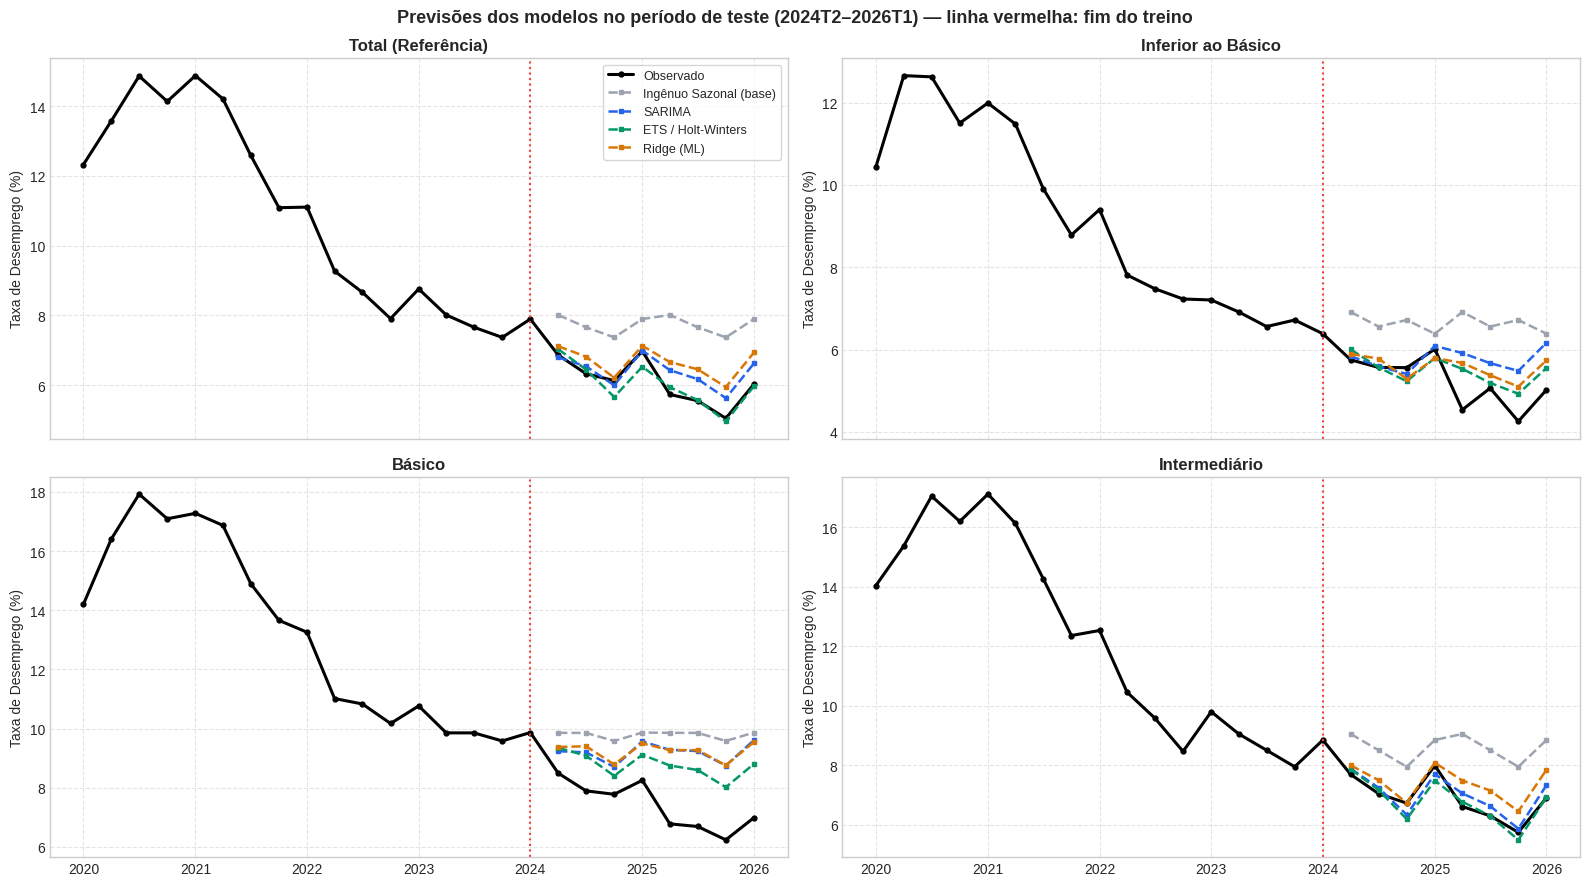


6. PREVISÃO PRELIMINAR COM O MELHOR MODELO DA VALIDAÇÃO (2026T2–2027T1)


#### **Tabela 5.5: Previsão preliminar da taxa de desemprego (%) — modelo de menor MASE na validação**

,Total (Referência) — SARIMA,Inferior ao Básico — ETS / Holt-Winters,Básico — SARIMA,Intermediário — Ridge (ML)
2026T2,5.54,4.68,6.61,6.06
2026T3,5.26,4.45,6.50,5.64
2026T4,4.77,4.20,6.03,4.96
2027T1,5.75,4.85,6.80,6.31


-> Configurações guardadas em 'config_modelos.json'
-> Métricas guardadas em 'resultados_teste_holdout.csv' e 'resultados_validacao_janela_expansiva.csv'


In [2]:
# ==============================================================================
# Etapa 2: Implementação dos Modelos de Previsão (Modelo Base e Candidatos)
# ==============================================================================

import itertools
import json
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# 1. CONFIGURAÇÕES DO EXPERIMENTO (registradas para reprodutibilidade)
# ------------------------------------------------------------------------------
CONFIG = {
    'series': ['Total (Referência)', 'Inferior ao Básico', 'Básico', 'Intermediário'],
    'frequencia': 'Trimestral (m = 4)',
    'periodo_total': '2012T1–2026T1 (57 trimestres)',
    'horizonte_teste': 8,                 # últimos 8 trimestres reservados para teste (2024T2–2026T1)
    'validacao_janela_expansiva': {'origens': 12, 'horizonte': 4},
    'sarima_grade': {'p': [0, 1, 2], 'd': [0, 1], 'q': [0, 1], 'P': [0, 1], 'D': [1], 'Q': [0, 1]},
    'sarima_criterio': 'AIC no conjunto de treino',
    'ets_configuracao': {'tendencia': 'aditiva amortecida', 'sazonalidade': 'aditiva', 'periodos_sazonais': 4},
    'ml_modelo': 'Regressão Ridge (alpha=1.0) sobre defasagens 1–4 + dummies de trimestre, previsão recursiva',
    'metricas': ['MAE', 'RMSE', 'MAPE (%)', 'MASE'],
    'semente': 42,
}
np.random.seed(CONFIG['semente'])
H = CONFIG['horizonte_teste']
M = 4

print("=" * 80)
print("1. PREPARAÇÃO DAS SÉRIES PARA A MODELAGEM")
print("=" * 80)

# Reaproveita a série da etapa de EDA (ts_principal) ou lê o ficheiro exportado
try:
    base = ts_principal[CONFIG['series']].copy()
except NameError:
    base = pd.read_csv('serie_temporal_desemprego_modelagem_estrita_pt.csv', index_col='Trimestre')[CONFIG['series']]
base.index = pd.PeriodIndex(base.index.str.replace('T', 'Q'), freq='Q')
base = base.astype(float).sort_index()

treino, teste = base.iloc[:-H], base.iloc[-H:]
print(f"-> Treino: {treino.index[0]} a {treino.index[-1]} ({len(treino)} trimestres)")
print(f"-> Teste:  {teste.index[0]} a {teste.index[-1]} ({len(teste)} trimestres)")


def rotulo(p):
    return str(p).replace('Q', 'T')


# ------------------------------------------------------------------------------
# 2. DEFINIÇÃO DOS MODELOS
# ------------------------------------------------------------------------------
def prev_ingenuo_sazonal(y, h):
    """Modelo de referência: repete o valor do mesmo trimestre do ano anterior."""
    ultimos = y.values[-M:]
    return np.array([ultimos[i % M] for i in range(h)])


def prev_ingenuo(y, h):
    """Passeio aleatório: repete o último valor observado."""
    return np.repeat(y.values[-1], h)


def ajustar_sarima(y):
    """Seleciona a ordem SARIMA(p,d,q)(P,D,Q)4 de menor AIC na grade definida."""
    g = CONFIG['sarima_grade']
    melhor = (np.inf, None, None)
    for p, d, q, P, D, Q in itertools.product(g['p'], g['d'], g['q'], g['P'], g['D'], g['Q']):
        try:
            res = SARIMAX(y.values, order=(p, d, q), seasonal_order=(P, D, Q, M),
                          trend='n', enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
            if np.isfinite(res.aic) and res.aic < melhor[0]:
                melhor = (res.aic, (p, d, q), (P, D, Q, M))
        except Exception:
            continue
    return melhor


def prev_sarima(y, h, ordem, ordem_saz):
    res = SARIMAX(y.values, order=ordem, seasonal_order=ordem_saz, trend='n',
                  enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return res.forecast(h)


def prev_ets(y, h):
    """Holt-Winters aditivo com tendência amortecida (ETS(A,Ad,A))."""
    res = ExponentialSmoothing(y.values, trend='add', damped_trend=True, seasonal='add',
                               seasonal_periods=M, initialization_method='estimated').fit(optimized=True)
    return res.forecast(h)


def matriz_atributos(valores, trimestres):
    X, alvo = [], []
    for t in range(M, len(valores)):
        dummies = [1.0 if trimestres[t] == k else 0.0 for k in (2, 3, 4)]
        X.append(list(valores[t - M:t][::-1]) + dummies)
        alvo.append(valores[t])
    return np.array(X), np.array(alvo)


def prev_ml_ridge(y, h):
    """Ridge sobre as 4 defasagens da 1ª diferença + dummies de trimestre (previsão recursiva)."""
    dif = np.diff(y.values)
    trim = np.array([p.quarter for p in y.index[1:]])
    X, alvo = matriz_atributos(dif, trim)
    modelo = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X, alvo)
    historico, nivel, prev = list(dif), y.values[-1], []
    prox = y.index[-1]
    for _ in range(h):
        prox = prox + 1
        dummies = [1.0 if prox.quarter == k else 0.0 for k in (2, 3, 4)]
        x = np.array(historico[-M:][::-1] + dummies).reshape(1, -1)
        d_hat = modelo.predict(x)[0]
        historico.append(d_hat)
        nivel = nivel + d_hat
        prev.append(nivel)
    return np.array(prev)


def metricas(real, prev, y_treino):
    real, prev = np.asarray(real), np.asarray(prev)
    erro = real - prev
    escala = np.mean(np.abs(y_treino.values[M:] - y_treino.values[:-M]))
    return {
        'MAE': np.mean(np.abs(erro)),
        'RMSE': np.sqrt(np.mean(erro ** 2)),
        'MAPE (%)': np.mean(np.abs(erro / real)) * 100,
        'MASE': np.mean(np.abs(erro)) / escala,
    }


# ------------------------------------------------------------------------------
# 3. SELEÇÃO DAS ORDENS SARIMA (AIC NO TREINO)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("2. SELEÇÃO AUTOMÁTICA DAS ORDENS SARIMA (CRITÉRIO AIC NO TREINO)")
print("=" * 80)
t0 = time.time()
ordens_sarima = {}
for serie in CONFIG['series']:
    aic, ordem, ordem_saz = ajustar_sarima(treino[serie])
    ordens_sarima[serie] = {'ordem': ordem, 'ordem_sazonal': ordem_saz, 'AIC': round(aic, 2)}
tabela_ordens = pd.DataFrame({
    s: {'Modelo selecionado': f"SARIMA{v['ordem']}x{v['ordem_sazonal']}", 'AIC (treino)': v['AIC']}
    for s, v in ordens_sarima.items()
}).T
display(Markdown("#### **Tabela 5.1: Ordens SARIMA selecionadas por série (grade de busca, menor AIC)**"))
display(tabela_ordens)
print(f"-> Busca em grade concluída em {time.time() - t0:.1f} s")

# ------------------------------------------------------------------------------
# 4. AVALIAÇÃO NO CONJUNTO DE TESTE (PREVISÃO DE 8 TRIMESTRES A PARTIR DE 2024T1)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("3. AVALIAÇÃO HOLD-OUT: PREVISÃO DOS ÚLTIMOS 8 TRIMESTRES")
print("=" * 80)

NOMES = ['Ingênuo', 'Ingênuo Sazonal (base)', 'SARIMA', 'ETS / Holt-Winters', 'Ridge (ML)']


def prever_todos(y, h, serie, ordens=None):
    o = ordens or ordens_sarima[serie]
    return {
        'Ingênuo': prev_ingenuo(y, h),
        'Ingênuo Sazonal (base)': prev_ingenuo_sazonal(y, h),
        'SARIMA': prev_sarima(y, h, o['ordem'], o['ordem_sazonal']),
        'ETS / Holt-Winters': prev_ets(y, h),
        'Ridge (ML)': prev_ml_ridge(y, h),
    }


previsoes_teste, linhas = {}, []
for serie in CONFIG['series']:
    previsoes_teste[serie] = prever_todos(treino[serie], H, serie)
    for nome in NOMES:
        linhas.append({'Série': serie, 'Modelo': nome,
                       **metricas(teste[serie], previsoes_teste[serie][nome], treino[serie])})
res_holdout = pd.DataFrame(linhas).set_index(['Série', 'Modelo'])


def destacar_melhor(df):
    """Destaca, em cada série, o menor erro de cada métrica."""
    estilo = pd.DataFrame('', index=df.index, columns=df.columns)
    for serie in df.index.get_level_values(0).unique():
        bloco = df.loc[serie]
        for col in df.columns:
            estilo.loc[(serie, bloco[col].idxmin()), col] = 'background-color:#bbf7d0; font-weight:bold'
    return estilo


display(Markdown("#### **Tabela 5.2: Métricas de erro no teste (2024T2–2026T1, horizonte de 1 a 8 trimestres)**"))
display(res_holdout.style.format('{:.3f}').apply(destacar_melhor, axis=None))

# ------------------------------------------------------------------------------
# 5. VALIDAÇÃO COM JANELA EXPANSIVA (ROLLING ORIGIN, h = 1 a 4)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("4. VALIDAÇÃO TEMPORAL COM JANELA EXPANSIVA (12 ORIGENS, HORIZONTE DE 4 TRIMESTRES)")
print("=" * 80)
n_origens, h_cv = CONFIG['validacao_janela_expansiva']['origens'], CONFIG['validacao_janela_expansiva']['horizonte']
linhas_cv = []
for serie in CONFIG['series']:
    y = base[serie]
    erros = {n: [] for n in NOMES}
    for k in range(n_origens):
        fim = len(y) - h_cv - (n_origens - 1 - k)
        y_tr, y_te = y.iloc[:fim], y.iloc[fim:fim + h_cv]
        prev = prever_todos(y_tr, len(y_te), serie)
        for n in NOMES:
            erros[n].append(metricas(y_te, prev[n], y_tr))
    for n in NOMES:
        media = pd.DataFrame(erros[n]).mean()
        linhas_cv.append({'Série': serie, 'Modelo': n, **media.to_dict()})
res_cv = pd.DataFrame(linhas_cv).set_index(['Série', 'Modelo'])
display(Markdown("#### **Tabela 5.3: Erro médio na validação com janela expansiva (12 origens: 2022T2–2025T1, h = 1–4)**"))
display(res_cv.style.format('{:.3f}').apply(destacar_melhor, axis=None))

# Resumo: melhor modelo por série (menor MASE na validação com janela expansiva)
melhor = res_cv['MASE'].groupby(level=0).idxmin().map(lambda x: x[1])
resumo = pd.DataFrame({
    'Melhor modelo (validação)': melhor,
    'MASE (validação)': res_cv['MASE'].groupby(level=0).min(),
    'MASE do modelo base (validação)': res_cv.xs('Ingênuo Sazonal (base)', level=1)['MASE'],
    'Melhor modelo (teste)': res_holdout['MASE'].groupby(level=0).idxmin().map(lambda x: x[1]),
}).loc[CONFIG['series']]
resumo['Ganho sobre a base (%)'] = (1 - resumo['MASE (validação)'] / resumo['MASE do modelo base (validação)']) * 100
display(Markdown("#### **Tabela 5.4: Resumo comparativo por série**"))
display(resumo.style.format({'MASE (validação)': '{:.3f}', 'MASE do modelo base (validação)': '{:.3f}',
                             'Ganho sobre a base (%)': '{:.1f}%'}))

# ------------------------------------------------------------------------------
# 6. GRÁFICOS: PREVISÕES NO PERÍODO DE TESTE
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("5. GRÁFICOS DAS PREVISÕES NO PERÍODO DE TESTE")
print("=" * 80)
cores = {'Ingênuo Sazonal (base)': '#9ca3af', 'SARIMA': '#2563eb', 'ETS / Holt-Winters': '#059669', 'Ridge (ML)': '#d97706'}
fig, eixos = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
inicio_plot = base.index.get_loc(pd.Period('2020Q1', freq='Q'))
datas = base.index.to_timestamp()
for ax, serie in zip(eixos.ravel(), CONFIG['series']):
    ax.plot(datas[inicio_plot:], base[serie].iloc[inicio_plot:], color='black', lw=2.2, marker='o', ms=3.5, label='Observado')
    for nome, cor in cores.items():
        ax.plot(datas[-H:], previsoes_teste[serie][nome], color=cor, lw=1.8, ls='--', marker='s', ms=3, label=nome)
    ax.axvline(datas[-H - 1], color='#ef4444', ls=':', lw=1.5)
    ax.set_title(serie, fontsize=12, fontweight='bold')
    ax.set_ylabel('Taxa de Desemprego (%)')
    ax.grid(True, ls='--', alpha=0.5)
eixos[0, 0].legend(loc='upper right', fontsize=9, frameon=True)
fig.suptitle('Previsões dos modelos no período de teste (2024T2–2026T1) — linha vermelha: fim do treino',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('painel5_pt_previsoes_teste.png', dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 7. PREVISÃO PRELIMINAR PARA OS PRÓXIMOS 4 TRIMESTRES (2026T2–2027T1)
# ------------------------------------------------------------------------------
print("\n" + "=" * 80)
print("6. PREVISÃO PRELIMINAR COM O MELHOR MODELO DA VALIDAÇÃO (2026T2–2027T1)")
print("=" * 80)
futuro_idx = [rotulo(base.index[-1] + i) for i in range(1, 5)]
prev_futuro = {}
for serie in CONFIG['series']:
    # As ordens SARIMA são reestimadas (AIC) com a base completa antes da previsão final
    aic, ordem, ordem_saz = ajustar_sarima(base[serie])
    ordens_sarima[serie]['ordem_base_completa'] = f"SARIMA{ordem}x{ordem_saz}"
    ordens_finais = {'ordem': ordem, 'ordem_sazonal': ordem_saz}
    prev_futuro[f"{serie} — {melhor[serie]}"] = prever_todos(base[serie], 4, serie, ordens_finais)[melhor[serie]]
tabela_futuro = pd.DataFrame(prev_futuro, index=futuro_idx)
display(Markdown("#### **Tabela 5.5: Previsão preliminar da taxa de desemprego (%) — modelo de menor MASE na validação**"))
display(tabela_futuro.style.format('{:.2f}'))

# ------------------------------------------------------------------------------
# 8. REGISTRO DAS CONFIGURAÇÕES E RESULTADOS
# ------------------------------------------------------------------------------
registro = {
    'config': CONFIG,
    'ordens_sarima': {s: {k: str(v) for k, v in o.items()} for s, o in ordens_sarima.items()},
    'melhor_modelo_validacao': melhor.to_dict(),
}
with open('config_modelos.json', 'w', encoding='utf-8') as f:
    json.dump(registro, f, ensure_ascii=False, indent=2)
res_holdout.to_csv('resultados_teste_holdout.csv')
res_cv.to_csv('resultados_validacao_janela_expansiva.csv')
print("-> Configurações guardadas em 'config_modelos.json'")
print("-> Métricas guardadas em 'resultados_teste_holdout.csv' e 'resultados_validacao_janela_expansiva.csv'")

# **Resultados**

Resultados parciais da modelagem (Etapa 3). As tabelas completas são geradas pela célula de código da seção **Modelos** (Tabelas 5.1 a 5.5 e Painel 5).

**Ordens SARIMA selecionadas (AIC no treino).** A estrutura **SARIMA(0,1,1)(0,1,1)₄**, o chamado modelo "airline", foi escolhida para Total, Inferior ao Básico e Básico. Para o Intermediário, foi escolhido o SARIMA(1,1,0)(0,1,1)₄. Ou seja, todas as séries precisaram de uma diferença simples e de uma diferença sazonal, o que indica a não estacionariedade das séries e confirma a sazonalidade trimestral observada na EDA. Os testes formais de estacionariedade serão realizados na próxima etapa.

**Comparação na validação com janela expansiva (MASE médio, h = 1 a 4 trimestres):**

| Série | Ingênuo sazonal (base) | Ingênuo | SARIMA | ETS/Holt-Winters | Ridge (ML) | Melhor | Ganho sobre a base |
|---|---|---|---|---|---|---|---|
| Total (Referência) | 0,818 | 0,523 | **0,356** | 0,408 | 0,362 | SARIMA | 56% |
| Inferior ao Básico | 0,722 | 0,457 | 0,510 | **0,408** | 0,458 | ETS | 43% |
| Básico | 0,852 | 0,506 | **0,475** | 0,511 | 0,515 | SARIMA | 44% |
| Intermediário | 0,779 | 0,537 | 0,329 | 0,368 | **0,294** | Ridge | 62% |

**Teste final (2024T2–2026T1, horizonte de 1 a 8 trimestres, MAE em p.p.):** o **ETS/Holt-Winters** teve o menor erro nas quatro séries: Total 0,20; Inferior ao Básico 0,39; Básico 1,38; Intermediário 0,22. O SARIMA ficou em segundo lugar, com 0,37, 0,59, 1,81 e 0,30. O modelo base errou entre 1,4 e 2,4 p.p.

**Análise dos resultados.**

* Todos os modelos de séries temporais **superaram com folga o modelo de referência**, com redução de 43% a 62% no MASE da validação. O ingênuo sazonal é um modelo fraco para estas séries porque ignora a **forte tendência de queda do desemprego desde 2021**. Por isso, até o ingênuo simples (último valor) tem desempenho melhor que ele.
* **Não há um único modelo vencedor.** Na validação, SARIMA, ETS e Ridge ficaram próximos, com diferenças de 0,04 a 0,10 no MASE. No teste de 8 trimestres, o ETS com tendência amortecida foi o melhor em todas as séries, porque acompanhou melhor a queda contínua do período 2024–2025.
* A série **Básico** foi a mais difícil. Houve uma queda brusca a partir de 2024T2 (de 9,9% para 8,5%) que nenhum modelo antecipou, e todos superestimaram a taxa no teste (MAPE de 19% a 26% nos modelos de séries temporais). Isso indica uma mudança de nível que deve ser investigada na próxima etapa.
* O **modelo de ML (Ridge)** foi viável apesar da base pequena: foi o melhor na validação do Intermediário e ficou próximo do SARIMA no Total. No horizonte de 8 trimestres, porém, perdeu desempenho por causa da propagação de erros na previsão recursiva. Com 57 observações, não se justificam modelos mais complexos, como redes neurais.

**Previsão preliminar (2026T2–2027T1, modelo de menor MASE na validação):** Total 5,54% → 5,26% → 4,77% → 5,75%; Inferior ao Básico 4,68% → 4,45% → 4,20% → 4,85%; Básico 6,61% → 6,50% → 6,03% → 6,80%; Intermediário 6,06% → 5,64% → 4,96% → 6,31%. A alta no 1º trimestre de 2027 reflete a sazonalidade usual do início do ano.

**Próximos passos (refinamento até a entrega final):** (i) testar combinações (*ensembles*) de SARIMA + ETS, já que os dois se complementam; (ii) incluir intervalos de previsão; (iii) tratar a pandemia (2020–2021) com variáveis de intervenção; (iv) avaliar modelos multivariados que usem a forte correlação entre as séries de escolaridade (r ≥ 0,96 entre as quatro séries); (v) reavaliar a série Básico após a quebra de nível de 2024.

# **Dicussão e Conclusão**

Conclusões; análise crítica dos resultados do trabalho (suas qualidades e limitações); alcance do objetivo inicial (a solução do problema); potenciais melhorias no projeto.

# **Apresentação**

Colocar os links do vídeo (apresentação com apoio de slides).

# **Referências**

ALVES, Jardel Augusto Gomes Rodrigues. *Uma análise cross-country sobre o desemprego: passado, presente e uma prospecção de futuro baseada em cenários*. 2024. Tese (Doutorado em Administração) – Faculdade de Economia, Administração, Contabilidade e Atuária, Universidade de São Paulo, São Paulo, 2024. DOI: 10.11606/T.12.2024.tde-18072024-094002.<br>

HOERL, Arthur E.; KENNARD, Robert W. Ridge regression: applications to nonorthogonal problems. *Technometrics*, v. 12, n. 1, p. 69-82, 1970. DOI: https://doi.org/10.1080/00401706.1970.10488635.<br>

HYNDMAN, Rob J.; KOEHLER, Anne B. Another look at measures of forecast accuracy. *International Journal of Forecasting*, v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001.<br>

INTERNATIONAL LABOUR ORGANIZATION. *Quick guide on interpreting the unemployment rate* (2019). Disponível em: https://www.ilo.org/publications/quick-guide-interpreting-unemployment-rate. Acesso em: 28 set. 2026.<br>

INTERNATIONAL LABOUR ORGANIZATION. *ILOSTAT: Data Explorer* (2026). Disponível em: https://ilostat.ilo.org/data/. Acesso em: 28 set. 2026.<br>

INTERNATIONAL LABOUR ORGANIZATION. *Unemployment rate by sex, age and education (%)* (2026). Disponível em: https://rshiny.ilo.org/dataexplorer52/?id=UNE_5EAP_SEX_AGE_EDU_RT_Q&ref_area=BRA. Acesso em: 28 set. 2026.<br>

MAHMUDAH, Umi. Predicting unemployment rates in Indonesia. *Economic Journal of Emerging Markets*, v. 9, n. 1, p. 20-28, 2017. DOI: 10.20885/ejem.vol9.iss1.art3.<br>

MORETTIN, Pedro Alberto; TOLOI, Clélia Maria de Castro. *Análise de séries temporais*. 3. ed. São Paulo: Blucher, 2018. v. 1.<br>

YAMACLI, Dilek Surekci; YAMACLI, Serhan. Estimation of the unemployment rate in Turkey: a comparison of the ARIMA and machine learning models including Covid-19 pandemic periods. *Heliyon*, v. 9, n. 1, e12796, 2023. DOI: 10.1016/j.heliyon.2023.e12796.